# CART Decision Tree with the Student Exam Result Dataset

In this notebook a **CART (Classification and Regression Tree)** model learns to predict whether a student will **Pass** or **Fail** an exam from their study habits.

What we will do:
1. Create the student dataset and inspect it.
2. Turn categorical text values into numeric columns.
3. Train a CART classifier that uses the Gini index to split.
4. Evaluate predictions with common metrics.
5. Draw the trained decision tree.
6. Predict results for new students.

Because the data is very small, this is meant for understanding the algorithm, not for real-world use.

## 1. Import required packages

pandas stores the data, matplotlib produces the plots, and scikit-learn supplies the tree model, the encoder and the evaluation tools.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", None)
plt.style.use("bmh")

## 2. Create the student exam data

Every row represents one student. The `Result` column is the target: **Pass** or **Fail**.

| Feature | Values |
|---|---|
| StudyHours | Low, Medium, High |
| Attendance | Poor, Average, Good |
| Sleep | Short, Adequate |
| Assignments | Incomplete, Complete |

In [2]:
student_data = {
    "StudyHours": [
        "Low", "Low", "Medium", "High", "High", "Medium",
        "Medium", "Low", "High", "Medium", "Low", "High",
        "Medium", "High", "Low", "Medium", "High", "Low"
    ],
    "Attendance": [
        "Poor", "Average", "Good", "Good", "Average", "Poor",
        "Average", "Good", "Poor", "Poor", "Good", "Good",
        "Average", "Poor", "Average", "Good", "Average", "Poor"
    ],
    "Sleep": [
        "Short", "Adequate", "Adequate", "Short", "Adequate", "Short",
        "Adequate", "Adequate", "Short", "Adequate", "Short", "Adequate",
        "Short", "Adequate", "Short", "Short", "Short", "Adequate"
    ],
    "Assignments": [
        "Incomplete", "Incomplete", "Complete", "Complete", "Incomplete", "Incomplete",
        "Complete", "Complete", "Complete", "Complete", "Incomplete", "Complete",
        "Incomplete", "Incomplete", "Complete", "Complete", "Complete", "Incomplete"
    ],
    "Result": [
        "Fail", "Fail", "Pass", "Pass", "Pass", "Fail",
        "Pass", "Pass", "Pass", "Fail", "Fail", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass", "Fail"
    ]
}

student_df = pd.DataFrame(student_data)
student_df.head()

,StudyHours,Attendance,Sleep,Assignments,Result
0,Low,Poor,Short,Incomplete,Fail
1,Low,Average,Adequate,Incomplete,Fail
2,Medium,Good,Adequate,Complete,Pass
3,High,Good,Short,Complete,Pass
4,High,Average,Adequate,Incomplete,Pass


In [3]:
row_total, col_total = student_df.shape
print(f"Number of students: {row_total}")
print(f"Number of columns: {col_total}")
print("\nEmpty cells per column:")
display(student_df.isna().sum().to_frame("Empty cells"))

print("Result counts:")
display(student_df["Result"].value_counts().rename_axis("Result").to_frame("Students"))

Number of students: 18
Number of columns: 5

Empty cells per column:


,Empty cells
StudyHours,0
Attendance,0
Sleep,0
Assignments,0
Result,0


Result counts:


,Students
Result,
Fail,9
Pass,9


## 3. View the result distribution

This chart shows how many students passed and how many failed. Here the two classes are evenly balanced.

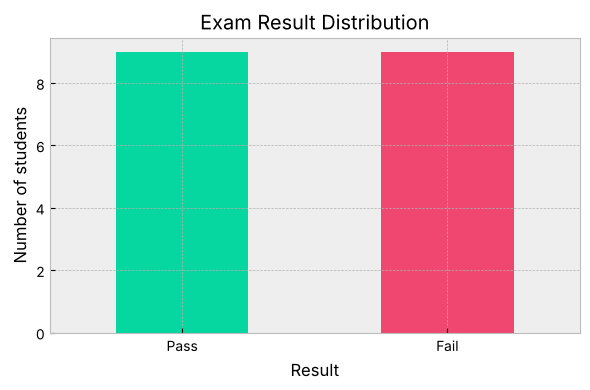

In [4]:
result_counts = student_df["Result"].value_counts().reindex(["Pass", "Fail"])

fig, ax_bar = plt.subplots(figsize=(6, 4))
result_counts.plot(kind="bar", color=["#06d6a0", "#ef476f"], ax=ax_bar)
ax_bar.set_title("Exam Result Distribution")
ax_bar.set_xlabel("Result")
ax_bar.set_ylabel("Number of students")
ax_bar.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4. Find the root split by hand

CART evaluates every possible rule and keeps the one whose child nodes are the most pure. Purity is scored with **Gini impurity**:

$$G = 1 - \sum_{c} p_c^{\,2}$$

`p_c` is the fraction of class *c* (`Pass` or `Fail`) in a node. For each rule we compute the Gini of the "true" branch and the "false" branch, take their size-weighted average, and see how much it lowers the impurity of the full dataset.

The rule with the **smallest weighted Gini** — the **largest Gini gain** — is chosen as the root.

In [5]:
outcome_col = "Result"
input_cols = ["StudyHours", "Attendance", "Sleep", "Assignments"]

def node_gini(node_rows):
    """Gini impurity of the outcome column for the given rows."""
    if node_rows.shape[0] == 0:
        return 0.0
    proportions = node_rows[outcome_col].value_counts(normalize=True)
    return 1 - proportions.pow(2).sum()

base_gini = node_gini(student_df)
print(f"Gini impurity of full dataset: {base_gini:.4f}")

Gini impurity of full dataset: 0.5000


In [6]:
split_log = []
n_students = len(student_df)

for column in input_cols:
    for level in sorted(student_df[column].unique()):
        true_branch = student_df[student_df[column] == level]
        false_branch = student_df[student_df[column] != level]

        true_gini = node_gini(true_branch)
        false_gini = node_gini(false_branch)
        avg_gini = (
            (len(true_branch) / n_students) * true_gini
            + (len(false_branch) / n_students) * false_gini
        )

        split_log.append({
            "Column": column,
            "Condition": f"{column} is {level}",
            "True Gini": true_gini,
            "False Gini": false_gini,
            "Weighted Gini": avg_gini,
            "Gini Gain": base_gini - avg_gini,
        })

split_summary = (
    pd.DataFrame(split_log)
    .sort_values("Weighted Gini", ascending=True)
    .reset_index(drop=True)
)

display(split_summary.round(4))

,Column,Condition,True Gini,False Gini,Weighted Gini,Gini Gain
0,Assignments,Assignments is Incomplete,0.2188,0.3200,0.2750,0.2250
1,Assignments,Assignments is Complete,0.3200,0.2188,0.2750,0.2250
2,StudyHours,StudyHours is High,0.2778,0.4444,0.3889,0.1111
3,StudyHours,StudyHours is Low,0.2778,0.4444,0.3889,0.1111
4,Attendance,Attendance is Poor,0.2778,0.4444,0.3889,0.1111
5,Attendance,Attendance is Good,0.2778,0.4444,0.3889,0.1111
6,Sleep,Sleep is Adequate,0.4938,0.4938,0.4938,0.0062
7,Sleep,Sleep is Short,0.4938,0.4938,0.4938,0.0062
8,StudyHours,StudyHours is Medium,0.5000,0.5000,0.5000,0.0000
9,Attendance,Attendance is Average,0.5000,0.5000,0.5000,0.0000


In [7]:
winning_split = split_summary.head(1)

print("Root split chosen by Gini impurity:")
display(winning_split)

Root split chosen by Gini impurity:


,Column,Condition,True Gini,False Gini,Weighted Gini,Gini Gain
0,Assignments,Assignments is Incomplete,0.21875,0.32,0.275,0.225


## 5. Separate, split and encode the data

The inputs and the outcome are pulled apart, then the raw rows are divided into training and test sets. The one-hot encoder learns its categories **from the training rows only**, so the test set stays unseen until evaluation.

In [8]:
inputs = student_df[input_cols]
outcomes = student_df[outcome_col]

inputs_train, inputs_test, outcomes_train, outcomes_test = train_test_split(
    inputs,
    outcomes,
    test_size=0.20,
    random_state=21,
    stratify=outcomes,
)

ohe_transformer = ColumnTransformer(
    transformers=[
        ("cat_encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False), input_cols)
    ]
)

inputs_train_ohe = ohe_transformer.fit_transform(inputs_train)
inputs_test_ohe = ohe_transformer.transform(inputs_test)
encoded_cols = ohe_transformer.get_feature_names_out()

print(f"Students in training set: {len(inputs_train)}")
print(f"Students in test set: {len(inputs_test)}")
display(pd.DataFrame(inputs_train_ohe, columns=encoded_cols).head())

Students in training set: 14
Students in test set: 4


,cat_encode__StudyHours_High,cat_encode__StudyHours_Low,cat_encode__StudyHours_Medium,cat_encode__Attendance_Average,cat_encode__Attendance_Good,cat_encode__Attendance_Poor,cat_encode__Sleep_Adequate,cat_encode__Sleep_Short,cat_encode__Assignments_Complete,cat_encode__Assignments_Incomplete
0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0


## 6. Train the CART model

Setting `criterion="gini"` tells scikit-learn to pick splits by Gini impurity. A maximum depth of 3 keeps the tree small enough to read and limits overfitting.

In [9]:
exam_classifier = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=21,
)

exam_classifier.fit(inputs_train_ohe, outcomes_train)
print("Exam result CART model is trained.")

Exam result CART model is trained.


## 7. Evaluate the model

Accuracy is the proportion of correct predictions. The classification report adds precision, recall and F1-score for both Pass and Fail.

With just 18 students, a different train/test split could give very different scores, so read these numbers as a demonstration only.

In [10]:
predicted_results = exam_classifier.predict(inputs_test_ohe)
model_accuracy = accuracy_score(outcomes_test, predicted_results)

print(f"Model accuracy on test students: {model_accuracy:.2%}\n")
print(classification_report(outcomes_test, predicted_results, zero_division=0))

Model accuracy on test students: 75.00%

              precision    recall  f1-score   support

        Fail       0.67      1.00      0.80         2
        Pass       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



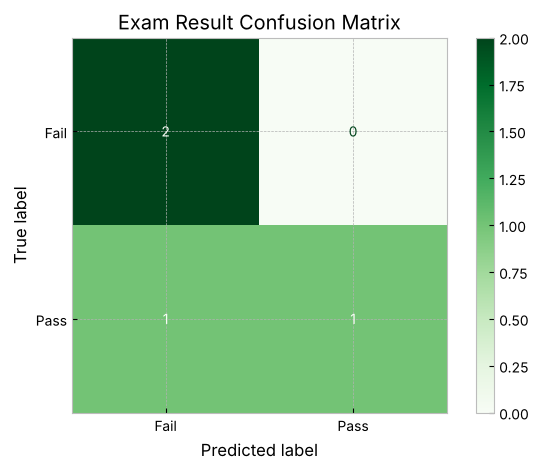

In [11]:
ConfusionMatrixDisplay.from_predictions(
    outcomes_test,
    predicted_results,
    labels=["Fail", "Pass"],
    cmap="Greens"
)
plt.title("Exam Result Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Display the decision tree

Each decision node checks one encoded feature. Students follow the left branch when the check is true and the right branch when it is false, until they reach a leaf with the predicted result.

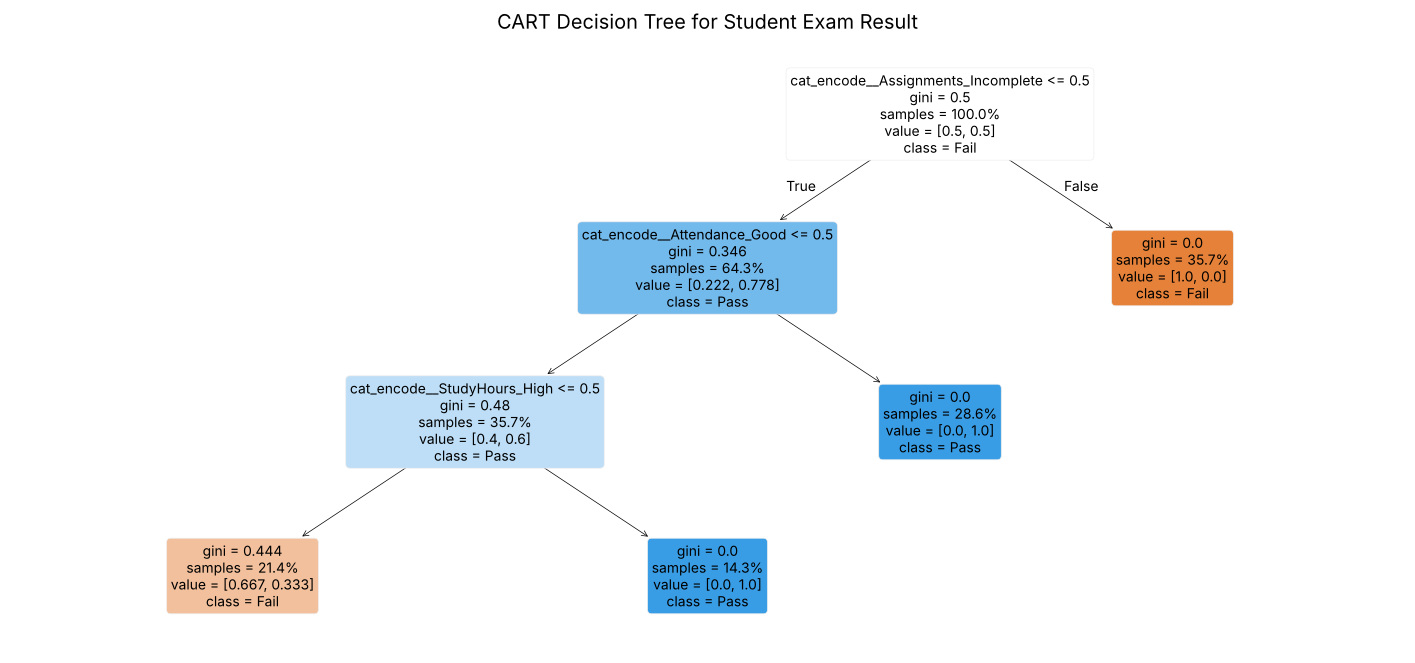

In [12]:
plt.figure(figsize=(18, 8))
plot_tree(
    exam_classifier,
    feature_names=encoded_cols,
    class_names=exam_classifier.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=10
)
plt.title("CART Decision Tree for Student Exam Result")
plt.show()

## 9. Predict results for new students

New students are encoded with the **already-fitted transformer** so their columns match the training layout exactly.

In [13]:
new_students = pd.DataFrame(
    {
        "StudyHours": ["High", "Low", "Medium"],
        "Attendance": ["Good", "Poor", "Average"],
        "Sleep": ["Adequate", "Short", "Adequate"],
        "Assignments": ["Complete", "Incomplete", "Complete"]
    }
)

new_students_ohe = ohe_transformer.transform(new_students)
new_students["Predicted Result"] = exam_classifier.predict(new_students_ohe)
new_students["Certainty"] = exam_classifier.predict_proba(new_students_ohe).max(axis=1)
new_students["Certainty"] = new_students["Certainty"].round(3).astype(str)
new_students

,StudyHours,Attendance,Sleep,Assignments,Predicted Result,Certainty
0,High,Good,Adequate,Complete,Pass,1.0
1,Low,Poor,Short,Incomplete,Fail,1.0
2,Medium,Average,Adequate,Complete,Fail,0.667


## 10. Summary

- CART learns a hierarchy of if/else rules directly from labelled examples.
- Gini impurity scores how mixed a node is and drives the choice of each split.
- One-hot encoding lets the tree work with categorical study-habit features.
- Keeping the tree shallow makes it easy to interpret and reduces overfitting.
- 18 students are enough to see how CART works, but real exam prediction would need much more data.